# Setup

In [1]:
import sys

from Part_2.course22p2.miniai.datasets import show_image

sys.path.insert(0, '/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/course22p2')

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
#|export
import torch
from torch import nn

from torch.utils.data import default_collate
from typing import Mapping

from miniai.training import *
from miniai.datasets import *

In [3]:
import pickle, gzip, math, os, time, shutil, torch, matplotlib as mpl, numpy as np
import pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from torch import tensor

from torch.utils.data import DataLoader
from typing import Mapping

In [4]:
mpl.rcParams['image.cmap'] = 'gray'

In [5]:
import os
os.getcwd()

'/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/Notebooks'

In [6]:
path = Path('../Data/MNIST')
path_gz = path/'mnist.pkl.gz'
with gzip.open(path_gz, 'rb') as f: ((x_train, y_train), (x_valid, y_valid), _) = pickle.load(f, encoding='latin-1')
x_train, y_train, x_valid, y_valid = map(tensor, [x_train, y_train, x_valid, y_valid])

/tmp/ipykernel_51823/98114708.py:3: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  with gzip.open(path_gz, 'rb') as f: ((x_train, y_train), (x_valid, y_valid), _) = pickle.load(f, encoding='latin-1')


# Convolutions  **[Notebook 1]**

In [7]:
x_imgs = x_train.view(-1,28,28) # this is to make the flatten n,784 -> n,24,24 , and the -1 is to keep the n
xv_imgs = x_valid.view(-1,28,28)

In [8]:
# set the image size/quality for matplotlib
mpl.rcParams['figure.dpi'] = 30

<Axes: >

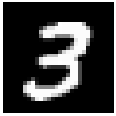

In [9]:
im3 = x_imgs[7]
show_image(im3)

In [10]:
top_edge = tensor([[-1,-1,-1],
                   [ 0, 0, 0],
                   [ 1, 1, 1]]).float()

<Axes: >

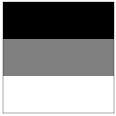

In [11]:
show_image(top_edge, noframe=False)

The filter will take any window of size 3×3 in our images, and if we name the pixel values like this:

$$\begin{matrix} a1 & a2 & a3 \\ a4 & a5 & a6 \\ a7 & a8 & a9 \end{matrix}$$

it will return $-a1-a2-a3+a7+a8+a9$.

In [12]:
df = pd.DataFrame(im3[:13,:23])
df.style.format(precision=2).set_properties(**{'font-size':'7pt'}).background_gradient('Greys')

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22
0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
3,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
5,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.15,0.17,0.41,1.00,0.99,0.99,0.99,0.99,0.99,0.68,0.02,0.00
6,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.17,0.54,0.88,0.88,0.98,0.99,0.98,0.98,0.98,0.98,0.98,0.98,0.62,0.05
7,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.70,0.98,0.98,0.98,0.98,0.99,0.98,0.98,0.98,0.98,0.98,0.98,0.98,0.23
8,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.43,0.98,0.98,0.90,0.52,0.52,0.52,0.52,0.74,0.98,0.98,0.98,0.98,0.23
9,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.02,0.11,0.11,0.09,0.00,0.00,0.00,0.00,0.05,0.88,0.98,0.98,0.67,0.03


here we can see the image pixels

In [13]:
im3[3:6,14:17].shape

torch.Size([3, 3])

In [14]:
im3[3:6,14:17],im3[7:10,14:17]

(tensor([[0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000],
         [0.9961, 0.9883, 0.9883]]),
 tensor([[0.9883, 0.9844, 0.9844],
         [0.5195, 0.5156, 0.5156],
         [0.0000, 0.0000, 0.0000]]))

here you can see what are the values of the pixels

In [15]:
(im3[3:6,14:17] * top_edge).sum()

tensor(2.9727)

In [16]:
(im3[7:10,14:17] * top_edge).sum()

tensor(-2.9570)

In [17]:
# make a function that does that
def apply_kernel(row,col,kernal,im=im3): return (im3[row-1:row+2,col-1:col+2] * kernal).sum()

In [18]:
apply_kernel(4,15,top_edge) # here it is giving the same answer

tensor(2.9727)

In [19]:
[[(i,j) for j in range(5)] for i in range(5)]

[[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4)],
 [(1, 0), (1, 1), (1, 2), (1, 3), (1, 4)],
 [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4)],
 [(3, 0), (3, 1), (3, 2), (3, 3), (3, 4)],
 [(4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]]

In [20]:
# now we make the kernal apply to all of the positions
rng = range(1,27) # we start from 1 and end at 27(excluded so 26) and remember that the last pixel index is 27 bec. we start from 0
top_edge_3 = tensor([[apply_kernel(i,j,top_edge,im3) for j in rng] for i in rng])
top_edge_3.shape , top_edge_3

(torch.Size([26, 26]),
 tensor([[ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
           0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
           0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
           0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
           0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
           0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
           0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
           0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
           0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
           0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
           0.0000,  0.1484,  0.3164,  0.7266,  1.5742,  2.3945,  2.972

<Axes: >

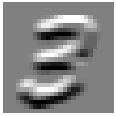

In [21]:
show_image(top_edge_3)

In [22]:
buttom_edge= tensor([[ 1, 1, 1],
                     [ 0, 0, 0],
                     [-1,-1,-1]]).float()

<Axes: >

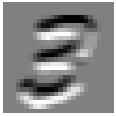

In [23]:
buttom_edge_3 = tensor([[apply_kernel(i,j,buttom_edge,im3) for j in rng] for i in rng])
show_image(buttom_edge_3)

In [24]:
left_edge = tensor([[-1,0,1],
                    [-1,0,1],
                    [-1,0,1]]).float()

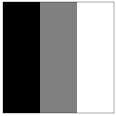

In [25]:
show_image(left_edge, noframe=False);

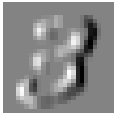

In [26]:
left_edge3 = tensor([[apply_kernel(i, j, left_edge) for j in rng] for i in rng])
show_image(left_edge3);

# Convolutions in pytorch

we are going to make it instead of loops as a MM

In [27]:
import torch.nn.functional as F
import torch

In [28]:
inp = im3[None,None,:,:].float()  # (1 (batch) ,1 (channel) ,28,28) that is a needed dimension
inp_unf = F.unfold(inp, (3,3))[0] # here we make it 3*3 patch in that shape (9,676) where every columns is a flatten patch of 3*3
inp_unf.shape

torch.Size([9, 676])

In [29]:
w = left_edge.view(-1) # here we also flatten the 3*3 kernel
w.shape

torch.Size([9])

In [30]:
out_unf = w@inp_unf # matrix multiply [9] @ [9, 676] → [676]
out_unf.shape

torch.Size([676])

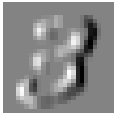

In [31]:
out = out_unf.view(26,26)
show_image(out);

In [32]:
# here lets see the difference in speed
%timeit -n 1 tensor([[apply_kernel(i,j,left_edge) for j in rng] for i in rng]);

4.86 ms ± 383 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [33]:
%timeit -n 100 (w@F.unfold(inp, (3,3))[0]).view(26,26);

19.8 μs ± 4.48 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [34]:
%timeit -n 100 F.conv2d(inp, left_edge[None,None]) # same as the MM we made but more optimizied

9.59 μs ± 3.53 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [35]:
diag1_edge = tensor([[ 0,-1, 1],
                     [-1, 1, 0],
                     [ 1, 0, 0]]).float()

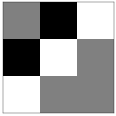

In [36]:
show_image(diag1_edge, noframe=False);

In [37]:
diag2_edge = tensor([[ 1,-1, 0],
                     [ 0, 1,-1],
                     [ 0, 0, 1]]).float()

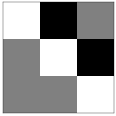

In [38]:
show_image(diag2_edge, noframe=False);

In [39]:
xb = x_imgs[:16][:,None]
xb.shape

torch.Size([16, 1, 28, 28])

In [40]:
edge_kernels = torch.stack([top_edge,buttom_edge, left_edge, diag1_edge, diag2_edge])[:,None]
edge_kernels.shape

torch.Size([5, 1, 3, 3])

In [41]:
batch_features = F.conv2d(xb, edge_kernels) # use the conv2d
batch_features.shape

torch.Size([16, 5, 26, 26])

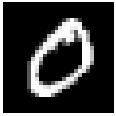

In [42]:
img0 = xb[1,0]
show_image(img0);

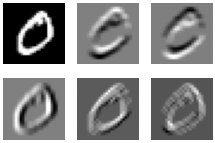

In [43]:
show_images([img0]+[batch_features[1,i] for i in range(5)])

# Stride and padding

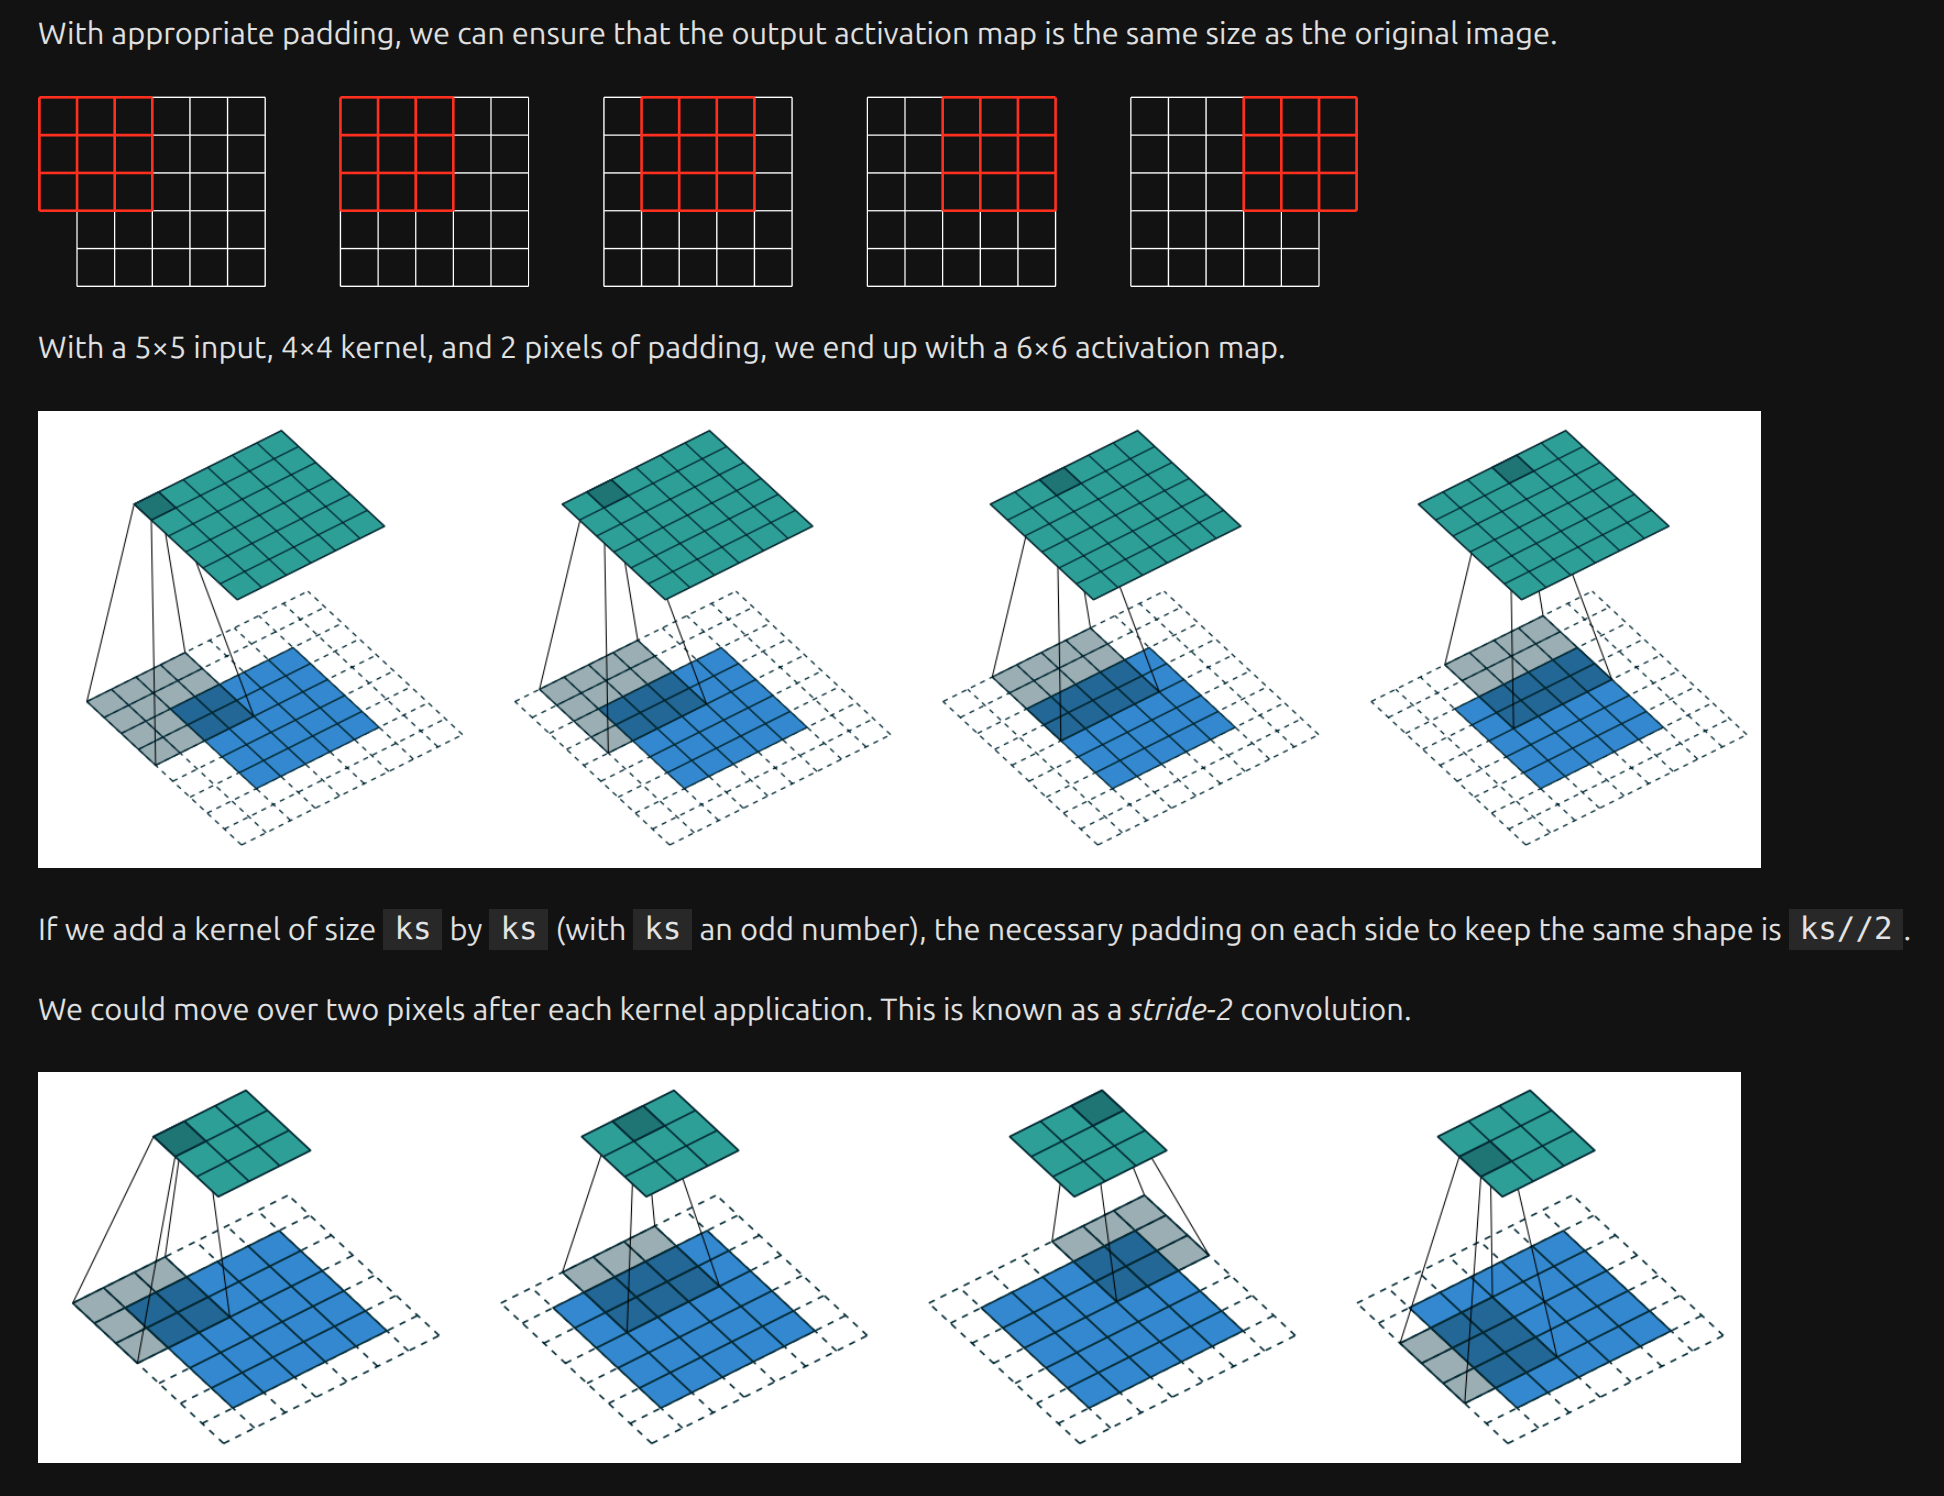

- kernel 3 → padding 1 → output same size  ✓
- kernel 5 → padding 2 → output same size  ✓
- kernel 7 → padding 3 → output same size  ✓

# Creating a CNN

In [46]:
n,m = x_train.shape
c = y_train.max()+1
nh = 50

In [47]:
# make a linear model
model = nn.Sequential(nn.Linear(m,nh), nn.ReLU(), nn.Linear(nh,10))

In [48]:
# make a cnn
broken_cnn = nn.Sequential(
    nn.Conv2d(1, 30, kernel_size=3, padding=1),   # [16,1,28,28] → [16,30,28,28]
    nn.ReLU(),
    nn.Conv2d(30, 10, kernel_size=3, padding=1)   # [16,30,28,28] → [16,10,28,28]
)
# why broken? ->  output is STILL an image shape! [16, 10, 28, 28] not [16,10] , we need flattening
broken_cnn(xb).shape

torch.Size([16, 10, 28, 28])

In [49]:
#|export
# here lets make a conv_fn, because we are always making relu after the conv2d to break non-linearity, so better make it at a function to make things easier
def conv(ni, nf, ks=3, stride=2, act=True):
    res = nn.Conv2d(ni, nf, stride=stride, kernel_size=ks, padding=ks//2)
    if act: res = nn.Sequential(res, nn.ReLU())
    return res

And  are The numbers that are inside the kernels ,  bias --> the learnable params

    conv(8, 16)   ← from 8 input channels to 16 output channels

    What happens:

    - We create 16 kernels (because we want 16 output features)

    - Each kernel has depth = 8
      → This means each kernel contains 8 small 3x3 mini-kernels

    How one kernel works:

    Take Kernel number 5 (this will become output feature map number 5)

    It has 8 mini 3x3 parts:

    Mini-kernel 1 → applied to input feature 1
    Mini-kernel 2 → applied to input feature 2
    Mini-kernel 3 → applied to input feature 3
    ...
    Mini-kernel 8 → applied to input feature 8

    At one position:

    - Take 3x3 patch from feature 1, multiply with Mini-kernel 1,
    sum the 9 numbers
    - Take 3x3 patch from feature 2, multiply with Mini-kernel 2,
     sum the 9 numbers
    - ...
    - Take 3x3 patch from feature 8, multiply with Mini-kernel 8,
     sum the 9 numbers

    Then add all 8 results together + add bias + ReLU

    → This gives ONE final number for this pixel in output feature map 5.

    We do the exact same thing for all 16 kernels.

    Result: 16 output feature maps

    And for the last con(16,10) We make ten kernels with the same
     approach.  And at the end we can conclude that each of these
      kernels when it is multiplied by the 16 features and then
       summed up  is  the probability of a specific number from
       zero to nine.

In [50]:
simple_cnn = nn.Sequential(
    conv(1 ,4),            #14x14
    conv(4 ,8),            #7x7
    conv(8 ,16),           #4x4
    conv(16,16),           #2x2
    conv(16,10, act=False), #1x1
    nn.Flatten(),
)

In [51]:
simple_cnn(xb).shape

torch.Size([16, 10])

In [52]:
x_imgs = x_train.view(-1,1,28,28) # -1 to have the same 1st dim (n_images) , (60000, 784)  →  (60000, 1, 28, 28)
xv_imgs = x_valid.view(-1,1,28,28)
train_ds,valid_ds = Dataset(x_imgs, y_train),Dataset(xv_imgs, y_valid)

In [54]:
#|export
def_device = 'mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu'

def to_device(x, device=def_device):
    if isinstance(x, torch.Tensor): return x.to(device) # check if it is tensor
    if isinstance(x, Mapping): return {k:v.to(device) for k,v in x.items()} # check if it is a dictionary
    return type(x)(to_device(o, device) for o in x) # whatever the type return the same thing with the items -> to device

def collate_device(b): return to_device(default_collate(b)) # moves the data to the GPU only when we get a batch, not all the data at once.

In [55]:
from torch import optim

bs = 256
lr = 0.4
train_dl,valid_dl = get_dls(train_ds, valid_ds, bs, collate_fn=collate_device)
opt = optim.SGD(simple_cnn.parameters(), lr=lr)

In [56]:
# train
loss,acc = fit(5, simple_cnn.to(def_device), F.cross_entropy, opt, train_dl, valid_dl)

0 0.381089670085907 0.8861999999046326
1 0.1815278367996216 0.9452000004768372
2 0.11704838066101074 0.9643000008583069
3 0.09925310652256011 0.9703999994277954
4 0.1456220285654068 0.9568000005722046


In [57]:
# train
opt = optim.SGD(simple_cnn.parameters(), lr=lr/4)
loss,acc = fit(5, simple_cnn.to(def_device), F.cross_entropy, opt, train_dl, valid_dl)

0 0.07831795163154602 0.9777999995231629
1 0.07588883395195008 0.9776999994277954
2 0.07747436237335205 0.977999999332428
3 0.07428378486633301 0.9790999994277955
4 0.07137378780841827 0.9787999994277954


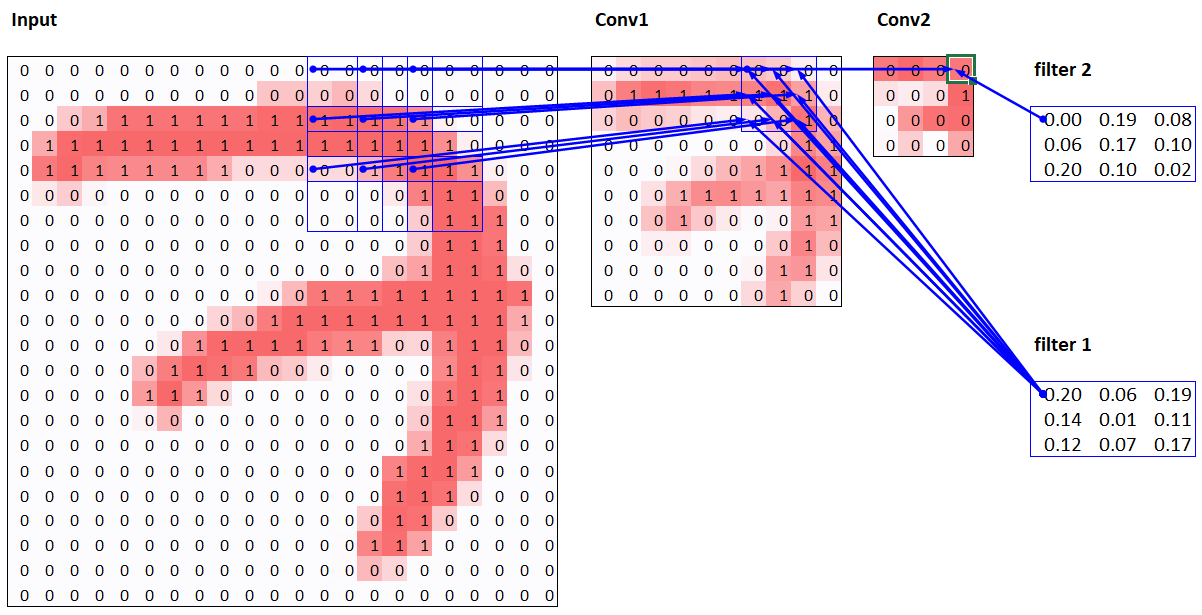

- Receptive Field is the area of the original image that influences one activation in a given layer.

- Early layers → small receptive field (e.g. 3×3)
- Deeper layers → much larger receptive field (e.g. 7×7, 11×11, etc.)

This is important because:

- Early layers detect small details (edges, lines)
- Later layers can see bigger patterns and shapes (because they "see" more of the image)

# Colored images

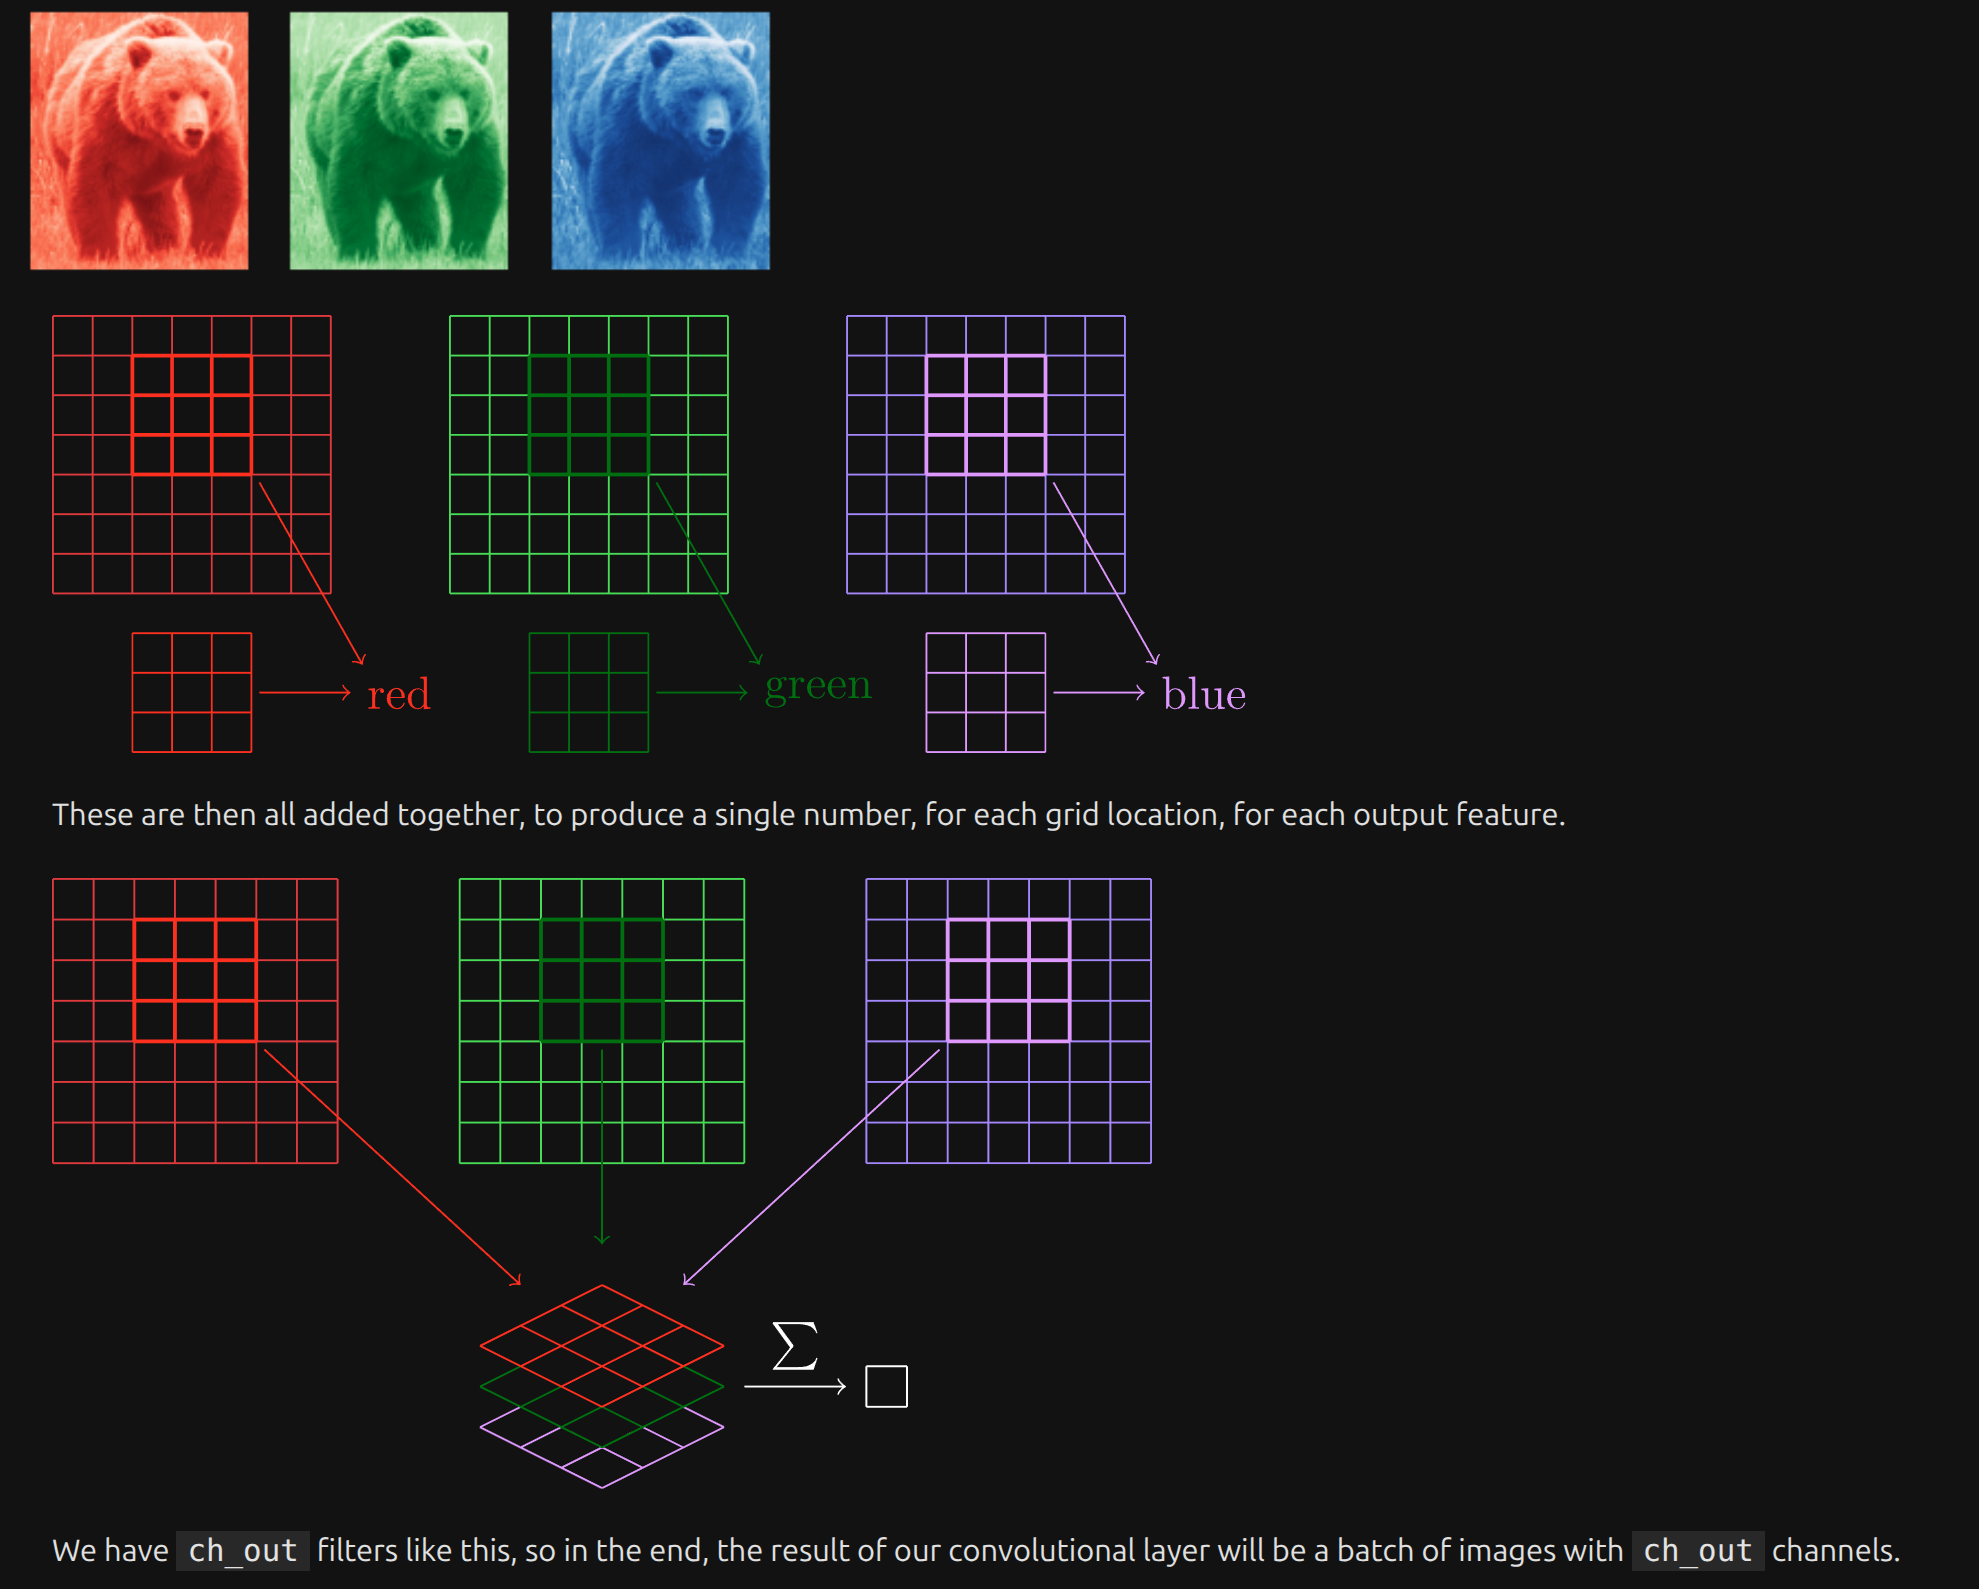

- "Whether we start with 1 channel or 3 channels, the convolution just mixes all the input features together to create new, better features."
- It is just the same as what we were doing in the grayscale one. But instead of having at the start one input feature we have three input features so as if we are just starting in almost like the second convolution [instead of 4 there is 3]  of the grey scale image that's it

# Autoencoders **[Notebook 2]**

# Data & Setup

In [61]:
import pickle,gzip,math,os,time,shutil,torch,matplotlib as mpl,numpy as np,matplotlib.pyplot as plt
import fastcore.all as fc
from collections.abc import Mapping
from pathlib import Path
from operator import attrgetter,itemgetter
from functools import partial

from torch import tensor,nn,optim
from torch.utils.data import DataLoader,default_collate
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from datasets import load_dataset,load_dataset_builder

from fastprogress import progress_bar,master_bar
from miniai.datasets import *
from miniai.training import *
from miniai.conv import *

In [62]:
x,y = 'image','label'
name = "fashion_mnist"
dsd = load_dataset(name)

In [65]:
dsd

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})

In [63]:
@inplace
def transformi(b): b[x] = [TF.to_tensor(o) for o in b[x]]

In [64]:
bs = 256
tds = dsd.with_transform(transformi)

    tds = dsd.with_transform(transformi)
    # applies to ALL splits at once
    # tds['train'] → transform runs ✅
    # tds['test']  → transform runs ✅

    # vs doing it per split:
    tds_train = dsd['train'].with_transform(transformi)
    tds_test  = dsd['test'].with_transform(transformi)

    # same result, just different ways to write it

    DataLoader → __getitem__ → transform → 16 images
                 ↑
                 with_transform hooks here
                 NOT on the whole dataset
                 lazy, on demand, one batch at a time****

In [66]:
tds

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})

In [71]:
tds['train']

Dataset({
    features: ['image', 'label'],
    num_rows: 60000
})

In [72]:
tds['train'][0]

{'image': tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000,

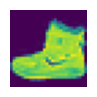

In [74]:
ds = tds['train']
img = ds[0]['image']
show_image(img, figsize=(1,1));

In [75]:
cf = collate_dict(ds) # this is a collate function

In [79]:
def collate_(b): return to_device(cf(b))

In [80]:
def data_loaders(dsd, bs, **kwargs): return {k:DataLoader(v, bs, **kwargs) for k,v in dsd.items()}

- k =  ('train', 'test')
-  v is the WHOLE SPLIT (all 60000 rows with both columns) -> {'image': PIL, 'label': 9} × 60000

In [82]:
dls = data_loaders(tds, bs, collate_fn=collate_)

In [83]:
dt = dls['train']
dv = dls['test']

In [84]:
xb,yb = next(iter(dt))

In [88]:
ds.features

{'image': Image(mode=None, decode=True),
 'label': ClassLabel(names=['T - shirt / top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'])}

In [86]:
labels = ds.features[y].names
labels

['T - shirt / top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [95]:
lbl_getter = itemgetter(*yb[:16]) # remember bs was = 256
yb[:16]

tensor([9, 0, 0, 3, 0, 2, 7, 2, 5, 5, 0, 9, 5, 5, 7, 9], device='cuda:0')

In [96]:
titles = lbl_getter(labels)
titles

('Ankle boot',
 'T - shirt / top',
 'T - shirt / top',
 'Dress',
 'T - shirt / top',
 'Pullover',
 'Sneaker',
 'Pullover',
 'Sandal',
 'Sandal',
 'T - shirt / top',
 'Ankle boot',
 'Sandal',
 'Sandal',
 'Sneaker',
 'Ankle boot')

Remember:

    d = {'a':1, 'b':2, 'c':3}

    ig = itemgetter('a', 'c')   # remembers which keys to grab
    ig(d)                        # → (1, 3)
    # same as (d['a'], d['c'])

    # works on lists too (by index):
    names = ['Top','Trouser','Dress','Boot']
    ig = itemgetter(0, 3)
    ig(names)   # → ('Top', 'Boot')

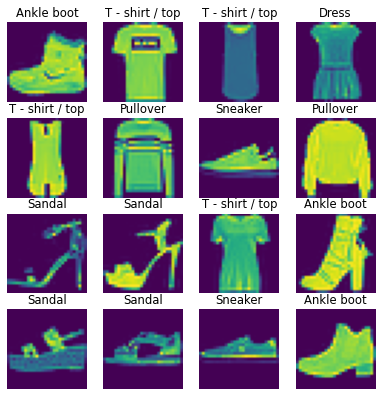

In [97]:
mpl.rcParams['figure.dpi'] = 70
show_images(xb[:16], imsize=1.7, titles=titles)

# Warmup - classify

In [98]:
from torch import optim

bs = 256
lr = 0.4

In [99]:
cnn = nn.Sequential(
    conv(1 ,4),            #14x14
    conv(4 ,8),            #7x7
    conv(8 ,16),           #4x4
    conv(16,16),           #2x2
    conv(16,10, act=False),
    nn.Flatten()).to(def_device)

In [101]:
def_device

'cuda'

In [100]:
opt = optim.SGD(cnn.parameters(), lr=lr)
loss,acc = fit(5, cnn, F.cross_entropy, opt, dt, dv)

0 0.7287458565711975 0.7462
1 0.5418913969278335 0.8031
2 0.45998536977767945 0.8329
3 0.4374288041114807 0.8437
4 0.4456339617729187 0.8419


In [102]:
dsd['train'][0]

{'image': <PIL.PngImagePlugin.PngImageFile image mode=L size=28x28>,
 'label': 9}

# Autoencoder

In [107]:
def deconv(ni, nf, ks=3, act=True):
    layers = [nn.UpsamplingNearest2d(scale_factor=2),
              nn.Conv2d(ni, nf, stride=1, kernel_size=ks, padding=ks//2)]
    if act: layers.append(nn.ReLU())
    return nn.Sequential(*layers)

    STEP 1: Nearest Neighbour Upsample (scale_factor=2)
    ─────────────────────────────────────────────────────
    INPUT (2x2):
    ┌──┬──┐
    │1 │2 │
    ├──┼──┤
    │3 │4 │
    └──┴──┘

    EACH PIXEL GETS COPIED INTO 2x2 BLOCK:
    ┌──┬──┬──┬──┐
    │1 │1 │2 │2 │  ← pixel 1 copied to 2x2
    ├──┼──┼──┼──┤
    │1 │1 │2 │2 │
    ├──┼──┼──┼──┤
    │3 │3 │4 │4 │  ← pixel 4 copied to 2x2
    ├──┼──┼──┼──┤
    │3 │3 │4 │4 │
    └──┴──┴──┴──┘
    OUTPUT (4x4) ← DOUBLED! ✓

    STEP 2: Conv (stride=1) to smooth it out:
    ┌──┬──┬──┬──┐        ┌──┬───┬───┬──┐
    │1 │1 │2 │2 │        │1 │1.3│1.7│2 │
    ├──┼──┼──┼──┤        ├──┼───┼───┼──┤
    │1 │1 │2 │2 │ ─────→ │1 │1.3│1.7│2 │
    ├──┼──┼──┼──┤        ├──┼───┼───┼──┤
    │3 │3 │4 │4 │        │2 │2.3│2.7│3 │
    ├──┼──┼──┼──┤        ├──┼───┼───┼──┤
    │3 │3 │4 │4 │        │2 │2.3│2.7│3 │
    └──┴──┴──┴──┘        └──┴───┴───┴──┘
    blocky copy           smooth ✓

    ## Here we use also 3*3 kernel with padding=1 to have the same output dimensions
     and in the kernal have the weights that we train.

    STEP 3: Relu

making a new fit() function

In [108]:
def eval(model, loss_func, valid_dl, epoch=0):
    model.eval()
    with torch.no_grad():
        tot_loss,count = 0.,0
        for xb,_ in valid_dl: # why don't use _ , because this is autoencoder not a classifier
            pred = model(xb)
            n = len(xb)
            count += n
            tot_loss += loss_func(pred,xb).item()*n
    print(epoch, f'loss :{tot_loss/count:.3f}')

In [109]:
def fit(epochs, model, loss_func, opt, train_dl, valid_dl):
    for epoch in range(epochs):
        model.train()
        for xb,_ in train_dl:
            loss = loss_func(model(xb), xb)
            loss.backward()
            opt.step()
            opt.zero_grad()
        eval(model, loss_func, valid_dl, epoch)

In [110]:
ae = nn.Sequential(   #28x28
    nn.ZeroPad2d(2),  #32x32
    conv(1,2),        #16x16
    conv(2,4),        #8x8
#     conv(4,8),        #4x4
#     deconv(8,4),      #8x8
    deconv(4,2),      #16x16
    deconv(2,1, act=False), #32x32
    nn.ZeroPad2d(-2), #28x28
    nn.Sigmoid()
).to(def_device)

In [111]:
eval(ae, F.mse_loss, dv)

0 0.155


In [112]:
opt = optim.SGD(ae.parameters(), lr=0.01)
fit(5, ae, F.mse_loss, opt, dt, dv)

0 0.135
1 0.119
2 0.110
3 0.100
4 0.086


In [113]:
opt = optim.SGD(ae.parameters(), lr=0.1)
fit(5, ae, F.mse_loss, opt, dt, dv)

0 0.038
1 0.031
2 0.028
3 0.026
4 0.024


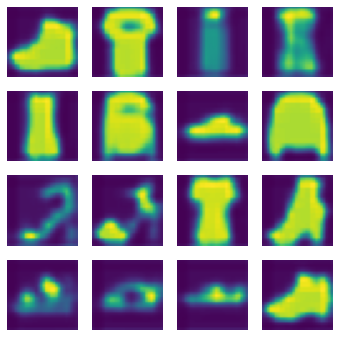

In [116]:
p = ae(xb)
show_images(p[:16].data.cpu(), imsize=1.5)

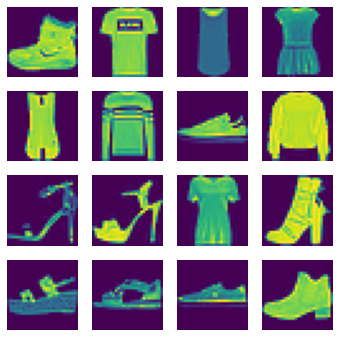

In [117]:
show_images(xb[:16].data.cpu(), imsize=1.5)